In [55]:
import os

os.environ["XLA_FLAGS"] = "--xla_gpu_cuda_data_dir=/home/everytee08/miniconda3/envs/tb-env"

In [56]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("GPU:", gpus)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [57]:
import tensorflow as tf

gpus = tf.config.experimental.list_physical_devices('GPU')

print("Detected GPU:", gpus)

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("GPU Ready")

Detected GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU Ready


In [58]:
import tensorflow as tf

gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

In [59]:
import zipfile
zf = "/home/everytee08/ta-tiara/CNN-ViT/archive (1).zip"
target_dir = "/home/everytee08/ta-tiara/CNN-ViT/dataset"
zfile = zipfile.ZipFile(zf)
zfile.extractall(target_dir)

In [60]:
import splitfolders

splitfolders.ratio(
"/home/everytee08/ta-tiara/CNN-ViT/dataset/TB_Chest_Radiography_Database", output="/home/everytee08/ta-tiara/CNN-ViT/dataset",
    seed=1337,
    ratio=(.7, .2, .1),
    group_prefix=None
)

Copying files: 4200 files [00:23, 176.36 files/s]


In [61]:
#Some Basic Imports
import matplotlib.pyplot as plt #For Visualization
import pandas as pd             # For handling data

In [62]:
train_path = "/home/everytee08/ta-tiara/CNN-ViT/dataset/train"
test_path = "/home/everytee08/ta-tiara/CNN-ViT/dataset/test"
valid_path = "/home/everytee08/ta-tiara/CNN-ViT/dataset/val"

In [63]:
batch_size = 16
img_height = 512
img_width = 512

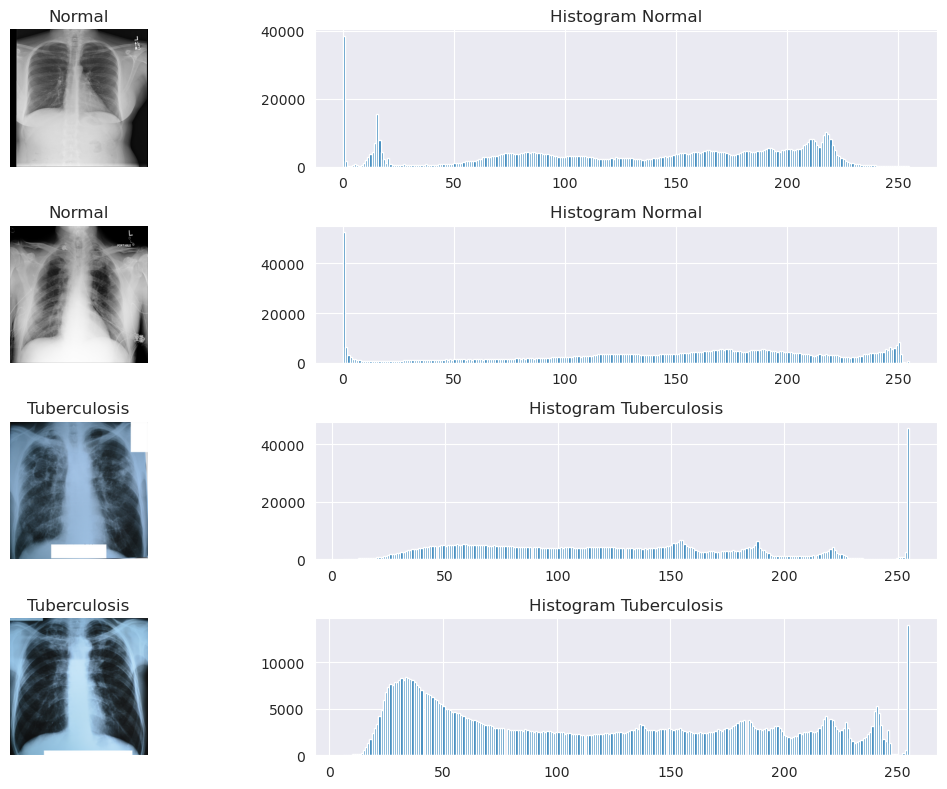

In [64]:
import os
import cv2
import matplotlib.pyplot as plt

base_path = "/home/everytee08/ta-tiara/CNN-ViT/dataset/train"

classes = ["Normal", "Tuberculosis"]

plt.figure(figsize=(12,8))

plot_idx = 1

for cls in classes:

    class_path = os.path.join(base_path, cls)
    files = os.listdir(class_path)

    # ambil 2 gambar tiap kelas
    for i in range(2):

        img = cv2.imread(os.path.join(class_path, files[i]))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # tampil gambar
        plt.subplot(4,2,plot_idx)
        plt.imshow(img)
        plt.title(cls)
        plt.axis("off")

        plot_idx += 1

        # histogram
        plt.subplot(4,2,plot_idx)
        plt.hist(img.ravel(), bins=256)
        plt.title(f"Histogram {cls}")

        plot_idx += 1

plt.tight_layout()
plt.show()

In [65]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
# pre proses gamma correction
def gamma_correction(img, gamma=1.0):
    img = img.astype(np.float32)

    if img.max() > 1.0:
        img /= 255.0

    return np.power(img, gamma)

def preprocess(img):
    img = gamma_correction(img, gamma=1.0)
    img = img.astype(np.float32)

    if img.max() > 1.0:
        img /= 255.0
    # img = img.astype(np.float32) / 255.0
    return img


image_gen = ImageDataGenerator(
    preprocessing_function=preprocess,
    fill_mode='nearest',
    rotation_range=5,
)

test_data_gen = ImageDataGenerator(
    preprocessing_function=preprocess
)

In [66]:
train = image_gen.flow_from_directory(
     train_path,
     target_size=(img_height, img_width),
     batch_size=batch_size,
     class_mode="binary",
     shuffle=True
)

test = test_data_gen.flow_from_directory(
      test_path,
      target_size=(img_height, img_width),
      shuffle=False,
      class_mode='binary',
      batch_size=batch_size,
      )

valid = test_data_gen.flow_from_directory(
      valid_path,
      target_size=(img_height, img_width),
      class_mode='binary',
      batch_size=batch_size,
      shuffle=False
      )

Found 3360 images belonging to 2 classes.
Found 421 images belonging to 2 classes.
Found 841 images belonging to 2 classes.


In [67]:
from collections import Counter
import os

for subset in ["train","val","test"]:
    normal = len(os.listdir(f"/home/everytee08/ta-tiara/CNN-ViT/dataset/{subset}/Normal"))
    tb = len(os.listdir(f"/home/everytee08/ta-tiara/CNN-ViT/dataset/{subset}/Tuberculosis"))

    print(subset, normal, tb)

train 2800 560
val 700 141
test 350 71


In [68]:
print(train.samples)
print(valid.samples)
print(test.samples)

3360
841
421


In [69]:
print(train.class_indices)
print(valid.class_indices)
print(test.class_indices)

{'Normal': 0, 'Tuberculosis': 1}
{'Normal': 0, 'Tuberculosis': 1}
{'Normal': 0, 'Tuberculosis': 1}


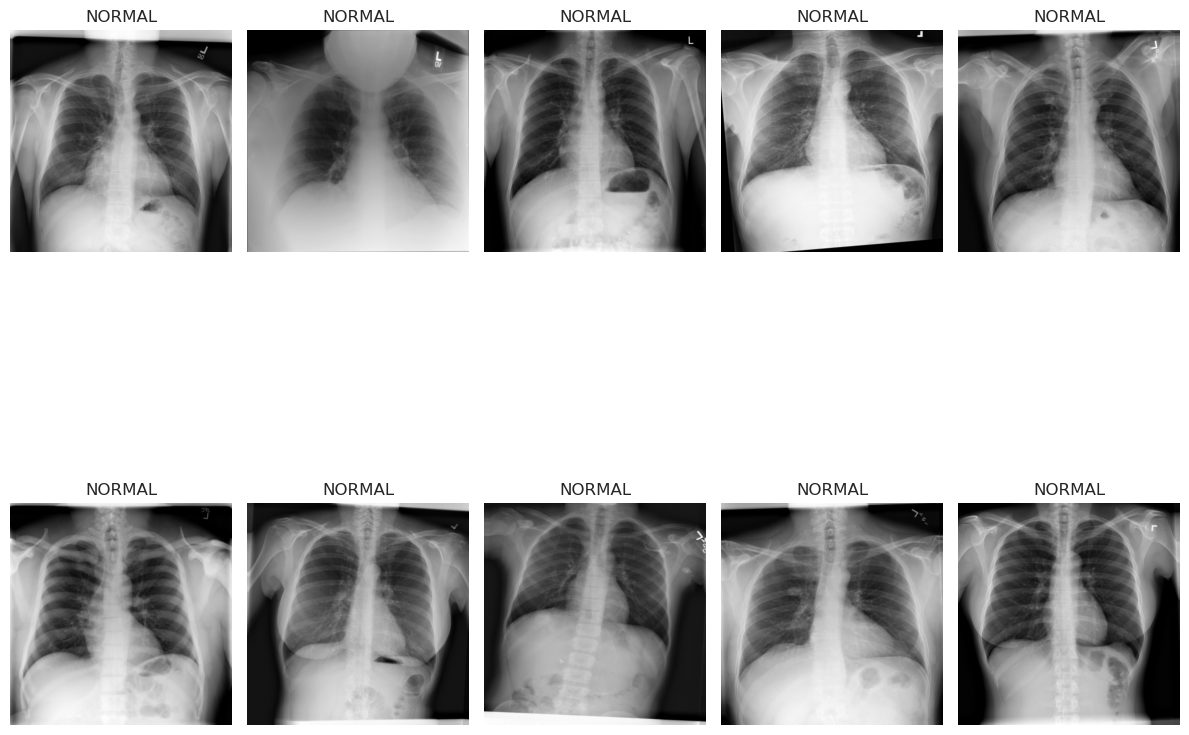

In [70]:
import numpy as np

plt.figure(figsize=(12,12))

X_batch, Y_batch = next(train)

dic = {0:'NORMAL',1:'TUBERCULOSIS'}

for i in range(10):
    plt.subplot(2,5,i+1)
    # plt.imshow(X_batch[i])
    plt.imshow(X_batch[i][:,:,0], cmap="gray")
    plt.title(dic.get(int(Y_batch[i])))
    plt.axis("off")

plt.tight_layout()
plt.show()

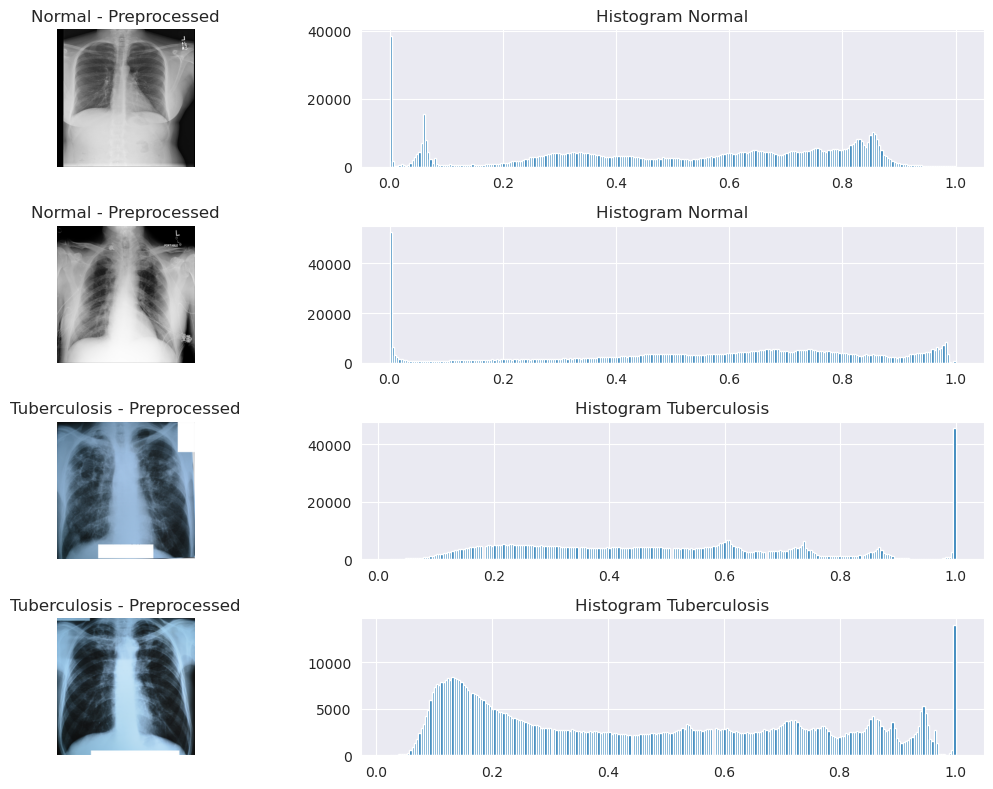

In [71]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

base_path = "/home/everytee08/ta-tiara/CNN-ViT/dataset/train"

classes = ["Normal", "Tuberculosis"]

plt.figure(figsize=(12,8))

plot_idx = 1

for cls in classes:

    class_path = os.path.join(base_path, cls)
    files = os.listdir(class_path)

    # ambil 2 gambar tiap kelas
    for i in range(2):

        # baca gambar
        img = cv2.imread(os.path.join(class_path, files[i]))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # preprocessing
        img = preprocess(img)

        # tampil gambar
        plt.subplot(4,2,plot_idx)
        plt.imshow(img)
        plt.title(f"{cls} - Preprocessed")
        plt.axis("off")

        plot_idx += 1

        # histogram
        plt.subplot(4,2,plot_idx)
        plt.hist(img.ravel(), bins=256)
        plt.title(f"Histogram {cls}")

        plot_idx += 1

plt.tight_layout()
plt.show()

In [72]:
x,y = next(train)
print(x.shape)

(16, 512, 512, 3)


In [73]:
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np

In [74]:
class_weight = {0: 1.0,
                1: 3.0}
print(class_weight)

{0: 1.0, 1: 3.0}


In [75]:
def transformer_block(x, num_heads=4, key_dim=64, ff_dim=1024, dropout=0.1):

    # Multi-head self attention
    attn_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim,
        dropout=dropout
    )(x, x)

    attn_output = Dropout(dropout)(attn_output)
    x = LayerNormalization(epsilon=1e-6)(x + attn_output)

    # Feed forward network
    ffn = Dense(ff_dim, activation='relu')(x)
    ffn = Dropout(dropout)(ffn)
    ffn = Dense(x.shape[-1])(ffn)
    ffn = Dropout(dropout)(ffn)

    return LayerNormalization(epsilon=1e-6)(x + ffn)

In [76]:
from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling1D
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

input_layer = Input(shape=(512,512,3))

# ResNet50
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_tensor=input_layer
)

# Freeze
for layer in base_model.layers:
    layer.trainable = False

x = base_model.output   # (None, 16, 16, 2048)

# Convert ke sequence (patch)
x = Reshape((256, 2048))(x)   # 16x16 = 256 patch

# projection
x = Dense(256)(x)


# Transformer Encoder
num_blocks = 2

for _ in range(num_blocks):
    x = transformer_block(x, ff_dim=512)

# Global pooling
x = GlobalAveragePooling1D()(x)

# Classifier
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(1, activation='sigmoid')(x)

model = Model(inputs=input_layer, outputs=output)

In [77]:
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.losses import binary_crossentropy
from tensorflow.keras.metrics import AUC, BinaryAccuracy, Precision, Recall


model.compile(
    optimizer= RMSprop(learning_rate=1e-4),
    # loss= BinaryFocalCrossentropy(),
    loss=binary_crossentropy,
    metrics= [
        BinaryAccuracy(threshold=0.569, name='accuracy'),
        AUC(name='auc'),
        AUC(name='pr_auc', curve='PR'),
        Precision(thresholds=0.569,name='precision'),
        Recall(thresholds=0.569,name='recall'),
    ]
)

model.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 512, 512, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 518, 518, 3)          0         ['input_2[0][0]']             
                                                                                                  
 conv1_conv (Conv2D)         (None, 256, 256, 64)         9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 256, 256, 64)         256       ['conv1_conv[0][0]']          
 on)                                                                                        

In [78]:
X_batch, y_batch = next(train)

print(X_batch.min())
print(X_batch.max())
print(X_batch.mean())

0.0
1.0
0.5261147




In [79]:
from tensorflow.keras.utils import plot_model
plot_model(model,show_shapes=True, show_layer_names=True, rankdir='TB', expand_nested=False)

In [80]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks_list = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        mode='min',
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        patience=3,
        factor=0.3,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_model.keras",
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

In [81]:
import numpy as np

class_weight = {0: 1.0,
                1: 3.0}
print(class_weight)

{0: 1.0, 1: 3.0}


In [82]:
history = model.fit(
        train,
        validation_data=valid,
        epochs=50,
        verbose=1,
        class_weight=class_weight,
        callbacks=callbacks_list
    )

Epoch 1/50
210/210 [==============================] - ETA: 0s - loss: 0.9302 - accuracy: 0.7991 - auc: 0.5111 - pr_auc: 0.1725 - precision: 0.1751 - recall: 0.0554
Epoch 1: val_loss improved from inf to 0.54458, saving model to best_model.keras
210/210 [==============================] - 357s 2s/step - loss: 0.9302 - accuracy: 0.7991 - auc: 0.5111 - pr_auc: 0.1725 - precision: 0.1751 - recall: 0.0554 - val_loss: 0.5446 - val_accuracy: 0.8323 - val_auc: 0.4986 - val_pr_auc: 0.1673 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - lr: 1.0000e-04
Epoch 2/50


2026-07-07 14:37:11.296672: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 50331712 bytes after encountering the first element of size 50331712 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


209/210 [============================>.] - ETA: 1s - loss: 0.8985 - accuracy: 0.8307 - auc: 0.5009 - pr_auc: 0.1670 - precision: 0.0833 - recall: 0.0018
Epoch 2: val_loss did not improve from 0.54458
210/210 [==============================] - 344s 2s/step - loss: 0.8994 - accuracy: 0.8304 - auc: 0.5009 - pr_auc: 0.1672 - precision: 0.0833 - recall: 0.0018 - val_loss: 0.5814 - val_accuracy: 0.8323 - val_auc: 0.5000 - val_pr_auc: 0.1677 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - lr: 1.0000e-04
Epoch 3/50
210/210 [==============================] - ETA: 0s - loss: 0.9000 - accuracy: 0.8244 - auc: 0.4969 - pr_auc: 0.1688 - precision: 0.2500 - recall: 0.0268
Epoch 3: val_loss did not improve from 0.54458
210/210 [==============================] - 332s 2s/step - loss: 0.9000 - accuracy: 0.8244 - auc: 0.4969 - pr_auc: 0.1688 - precision: 0.2500 - recall: 0.0268 - val_loss: 0.5462 - val_accuracy: 0.8323 - val_auc: 0.5000 - val_pr_auc: 0.1677 - val_precision: 0.0000e+00 - val_recall:

<Axes: >

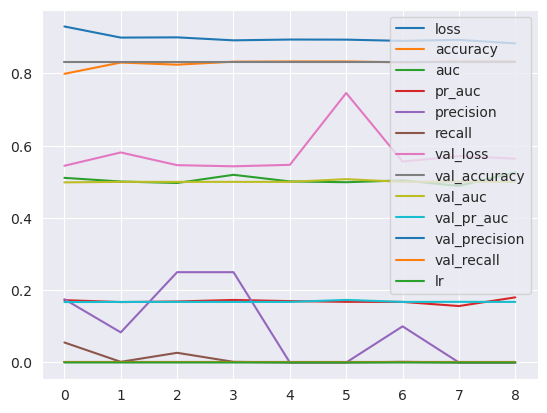

In [83]:
pd.DataFrame(history.history).plot()

In [84]:
# Unfreeze 30 layer terakhir
for layer in base_model.layers[:-30]:
     layer.trainable = False

for layer in base_model.layers[-30:]:
    layer.trainable = True

In [85]:
model.compile(
    optimizer=RMSprop(1e-6),

    loss='binary_crossentropy',

    metrics=[
        BinaryAccuracy(name='accuracy'),
        AUC(name='auc'),
        AUC(name='pr_auc', curve='PR'),
        Precision(name='precision'),
        Recall(name='recall')
    ]
)

In [86]:
history_finetune = model.fit(
    train,
    validation_data=valid,
    epochs=50,
    class_weight=class_weight,
    callbacks=callbacks_list,
    verbose=1
)

Epoch 1/50
210/210 [==============================] - ETA: 0s - loss: 0.8665 - accuracy: 0.8188 - auc: 0.5873 - pr_auc: 0.2337 - precision: 0.3008 - recall: 0.0661
Epoch 1: val_loss did not improve from 0.54311
210/210 [==============================] - 355s 2s/step - loss: 0.8665 - accuracy: 0.8188 - auc: 0.5873 - pr_auc: 0.2337 - precision: 0.3008 - recall: 0.0661 - val_loss: 0.5722 - val_accuracy: 0.8323 - val_auc: 0.3761 - val_pr_auc: 0.1463 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - lr: 1.0000e-06
Epoch 2/50


2026-07-07 15:27:21.652521: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 50331712 bytes after encountering the first element of size 50331712 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


210/210 [==============================] - ETA: 0s - loss: 0.7862 - accuracy: 0.8560 - auc: 0.7857 - pr_auc: 0.5061 - precision: 0.6939 - recall: 0.2429
Epoch 2: val_loss did not improve from 0.54311
210/210 [==============================] - 327s 2s/step - loss: 0.7862 - accuracy: 0.8560 - auc: 0.7857 - pr_auc: 0.5061 - precision: 0.6939 - recall: 0.2429 - val_loss: 0.6240 - val_accuracy: 0.8597 - val_auc: 0.9361 - val_pr_auc: 0.8463 - val_precision: 0.5520 - val_recall: 0.8652 - lr: 1.0000e-06
Epoch 3/50
210/210 [==============================] - ETA: 0s - loss: 0.6762 - accuracy: 0.8982 - auc: 0.9085 - pr_auc: 0.7438 - precision: 0.7535 - recall: 0.5786
Epoch 3: val_loss improved from 0.54311 to 0.43272, saving model to best_model.keras
210/210 [==============================] - 336s 2s/step - loss: 0.6762 - accuracy: 0.8982 - auc: 0.9085 - pr_auc: 0.7438 - precision: 0.7535 - recall: 0.5786 - val_loss: 0.4327 - val_accuracy: 0.9560 - val_auc: 0.9860 - val_pr_auc: 0.9583 - val_preci

In [87]:
model.evaluate(test)

# Simpan model
model.save("final_model.keras")

27/27 [==============================] - 16s 558ms/step - loss: 0.0175 - accuracy: 0.9952 - auc: 0.9998 - pr_auc: 0.9991 - precision: 1.0000 - recall: 0.9718


<Axes: >

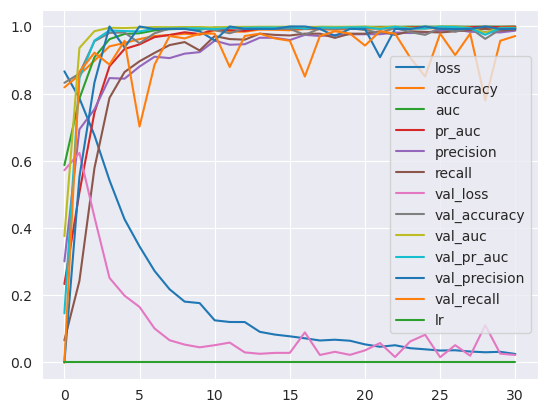

In [88]:
pd.DataFrame(history_finetune.history).plot()

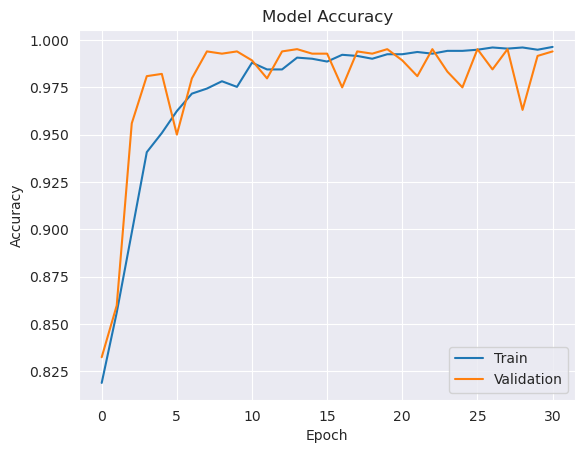

In [89]:
plt.plot(history_finetune.history['accuracy'])
plt.plot(history_finetune.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

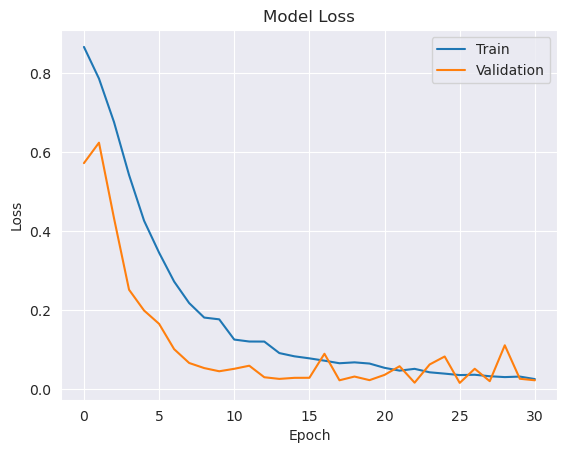

In [90]:
plt.plot(history_finetune.history['loss'])
plt.plot(history_finetune.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

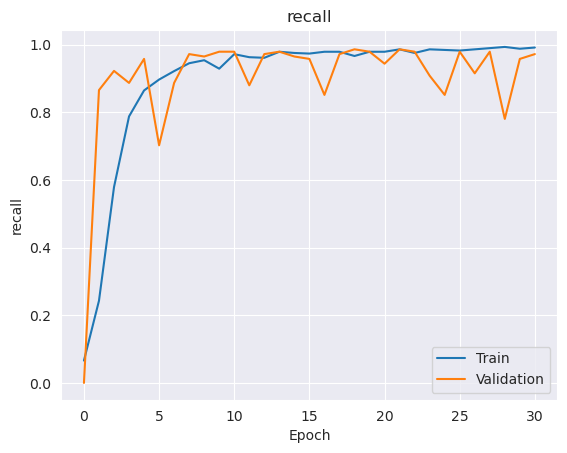

In [91]:
plt.plot(history_finetune.history['recall'])
plt.plot(history_finetune.history['val_recall'])
plt.title('recall')
plt.ylabel('recall')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

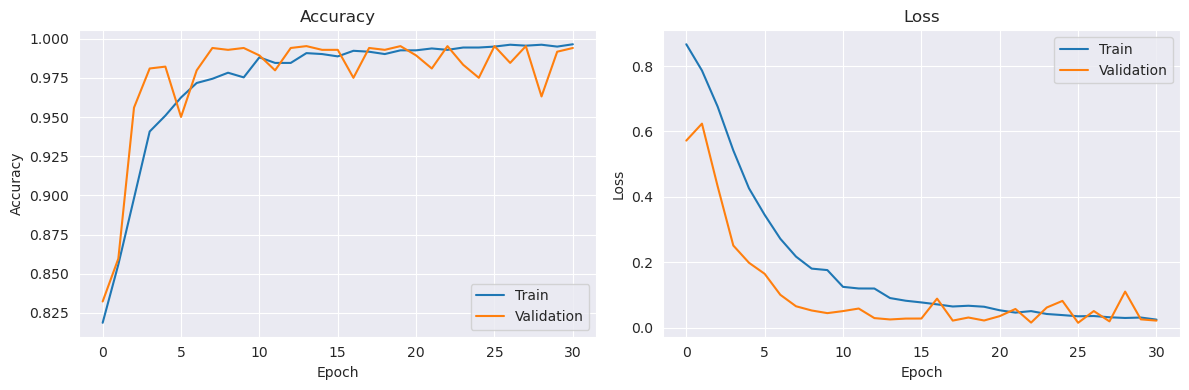

In [92]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12,4))

# Accuracy
ax[0].plot(history_finetune.history['accuracy'], label='Train')
ax[0].plot(history_finetune.history['val_accuracy'], label='Validation')
ax[0].set_title('Accuracy')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Accuracy')
ax[0].legend()

# Loss
ax[1].plot(history_finetune.history['loss'], label='Train')
ax[1].plot(history_finetune.history['val_loss'], label='Validation')
ax[1].set_title('Loss')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss')
ax[1].legend()

plt.tight_layout()
plt.show()

In [93]:
test_acc = model.evaluate(test)
metrics=[
    "accuracy",
    tf.keras.metrics.AUC(name='auc'),
    tf.keras.metrics.Precision(name='precision'),
    tf.keras.metrics.Recall(name='recall')
]


27/27 [==============================] - 16s 556ms/step - loss: 0.0175 - accuracy: 0.9952 - auc: 0.9998 - pr_auc: 0.9991 - precision: 1.0000 - recall: 0.9718


In [94]:
threshold = 0.569
pred = model.predict(test, verbose=1)

predictions = pred.copy()
predictions[predictions <= threshold] = 0
predictions[predictions > threshold] = 1

27/27 [==============================] - 18s 527ms/step


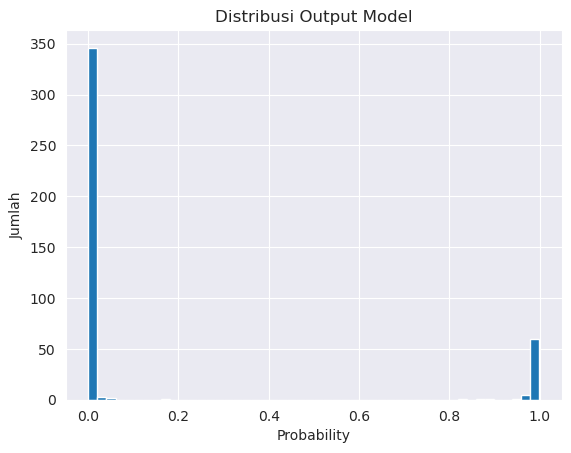

In [95]:
import matplotlib.pyplot as plt

plt.hist(pred, bins=50)
plt.title("Distribusi Output Model")
plt.xlabel("Probability")
plt.ylabel("Jumlah")
plt.show()

In [96]:
test_accu = model.evaluate(test)
print('The testing accuracy is :',test_accu[1]*100, '%')

27/27 [==============================] - 16s 537ms/step - loss: 0.0175 - accuracy: 0.9952 - auc: 0.9998 - pr_auc: 0.9991 - precision: 1.0000 - recall: 0.9718
The testing accuracy is : 99.52493906021118 %


In [97]:
from sklearn.metrics import confusion_matrix
y_true = test.classes
y_prob = model.predict(test).ravel()
y_pred = (y_prob >= threshold).astype(int)
cm = confusion_matrix(y_true, y_pred)
print(cm)

27/27 [==============================] - 17s 632ms/step
[[350   0]
 [  2  69]]


<Axes: >

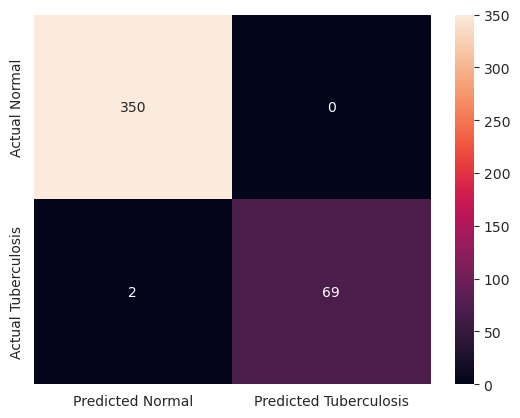

In [98]:
from sklearn.metrics import classification_report,confusion_matrix

cm = pd.DataFrame(data=confusion_matrix(test.classes, predictions, labels=[0, 1]),index=["Actual Normal", "Actual Tuberculosis"],
columns=["Predicted Normal", "Predicted Tuberculosis"])

import seaborn as sns
sns.heatmap(cm,annot=True,fmt="d")

In [99]:
print(classification_report(y_true=test.classes,y_pred=predictions,target_names =['NORMAL','TUBERCULOSIS']))

              precision    recall  f1-score   support

      NORMAL       0.99      1.00      1.00       350
TUBERCULOSIS       1.00      0.97      0.99        71

    accuracy                           1.00       421
   macro avg       1.00      0.99      0.99       421
weighted avg       1.00      1.00      1.00       421



In [100]:
from sklearn.metrics import f1_score
import numpy as np

y_true = valid.classes
y_prob = model.predict(valid).ravel()

thresholds = np.arange(0.1, 0.9, 0.01)

best_thresh = 0
best_f1 = 0

for t in thresholds:
    y_pred = np.array(y_prob >= t).astype(int)
    f1 = f1_score(y_true, y_pred)

    if f1 > best_f1:
        best_f1 = f1
        best_thresh = t

print("Best Threshold:", best_thresh)
print("Best F1 Score:", best_f1)

53/53 [==============================] - 29s 528ms/step
Best Threshold: 0.11
Best F1 Score: 0.9893238434163701


In [101]:
from sklearn.metrics import recall_score
import numpy as np

y_true = valid.classes
y_prob = model.predict(valid).ravel()

thresholds = np.arange(0.1, 0.9, 0.01)

best_recall = 0
best_threshold_recall = 0


for t in thresholds:
    y_pred = np.array(y_prob >= t).astype(int)
    rec = recall_score(y_true, y_pred)

    if rec > best_recall:
        best_recall = rec
        best_threshold_recall = t

print("Best Threshold :", best_threshold_recall)
print("Best Recall : ", best_recall)

53/53 [==============================] - 29s 535ms/step
Best Threshold : 0.1
Best Recall :  0.9858156028368794


In [102]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
import numpy as np

# prediksi model
y_pred = model.predict(test)

# ubah probabilitas jadi 0/1
y_pred = (y_pred > 0.5).astype(int)

# label asli
y_true = test.classes

# hitung metric
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print("Accuracy :", accuracy * 100)
print("Precision:", precision * 100)
print("Recall   :", recall * 100)
print("F1-Score :", f1 * 100)

27/27 [==============================] - 15s 514ms/step
Accuracy : 99.5249406175772
Precision: 100.0
Recall   : 97.1830985915493
F1-Score : 98.57142857142858


1/1 [==============================] - 3s 3s/step


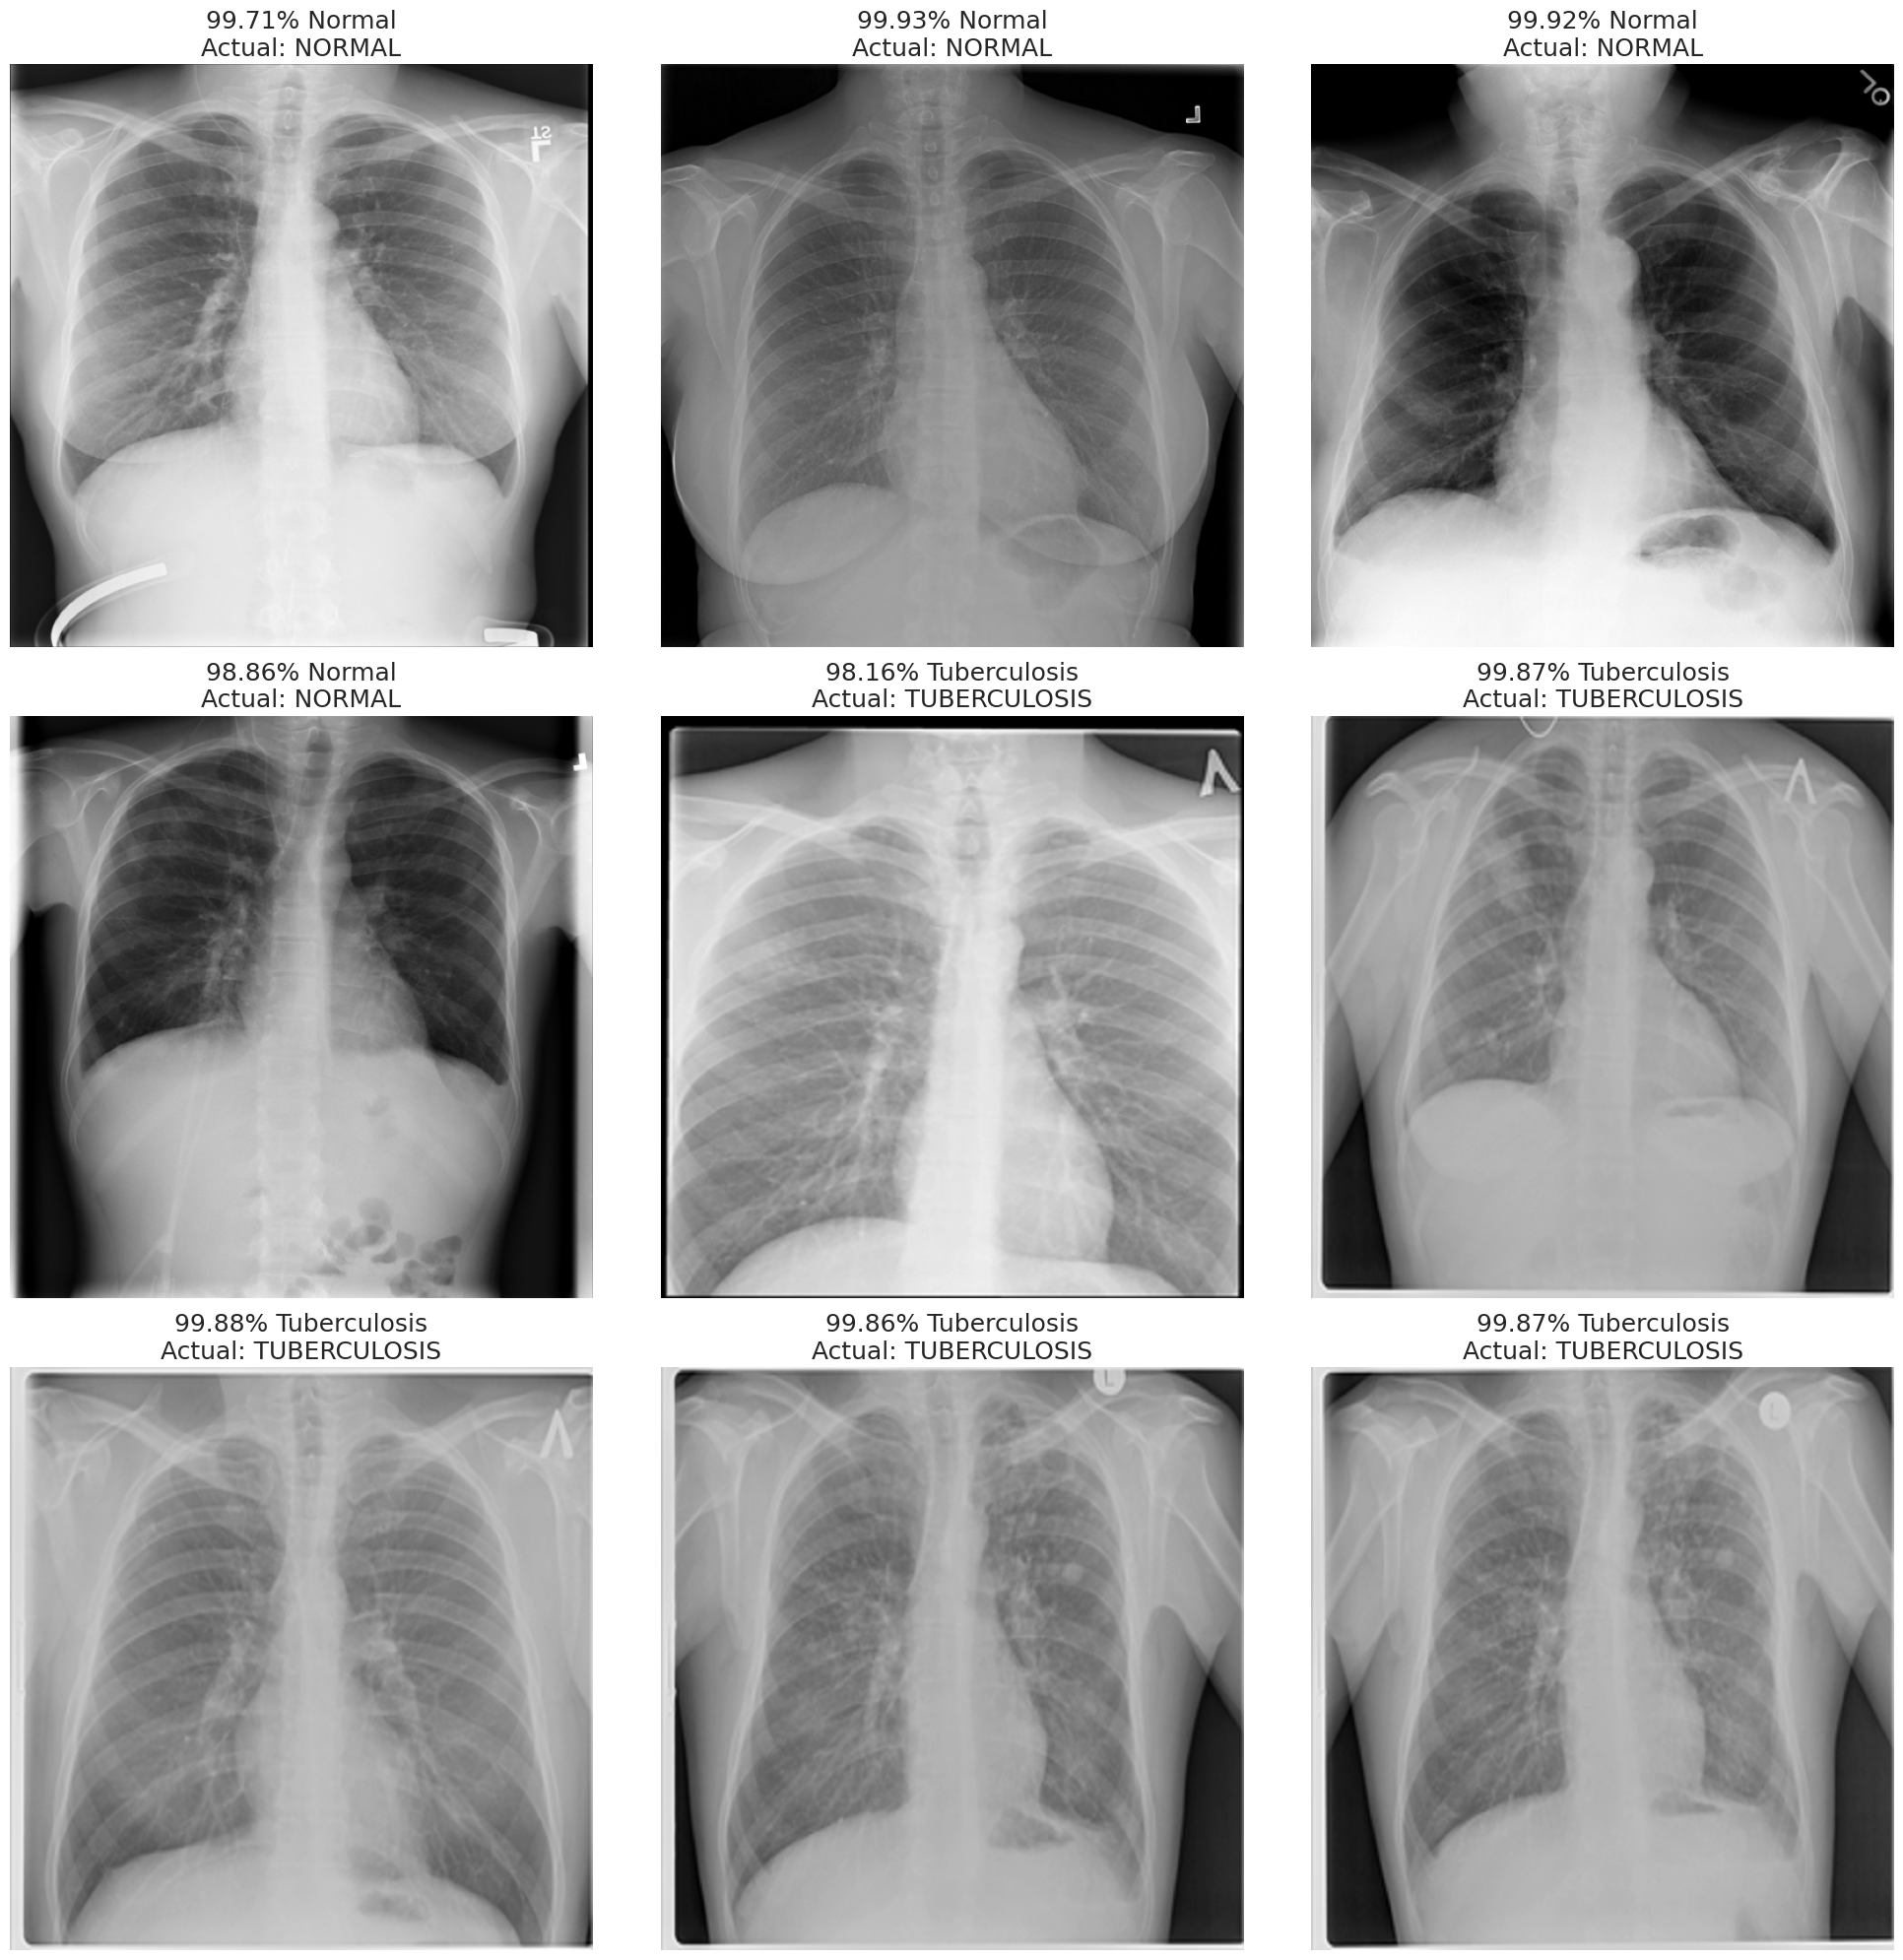

In [103]:
test.reset()

imgs = []
labels = []

count_tb = 0
count_normal = 0

for i in range(len(test)):
    x_batch, y_batch = test[i]

    for j in range(len(y_batch)):
        if y_batch[j] == 1 and count_tb < 5:
            imgs.append(x_batch[j])
            labels.append(y_batch[j])
            count_tb += 1

        elif y_batch[j] == 0 and count_normal < 4:
            imgs.append(x_batch[j])
            labels.append(y_batch[j])
            count_normal += 1

        if len(imgs) == 9:
            break
    if len(imgs) == 9:
        break

imgs = np.array(imgs)
labels = np.array(labels)

pred = model.predict(imgs)

plt.figure(figsize=(20,20))

for i in range(len(labels)):
    plt.subplot(3,3,i+1)

    score = pred[i,0]

    if score >= best_thresh:
        pred_label = "Tuberculosis"
        conf = score
    else:
        pred_label = "Normal"
        conf = 1-score

    plt.title(
        f"{conf:.2%} {pred_label}\nActual: {dic[int(labels[i])]}",
        fontsize=18
    )

    plt.imshow(imgs[i][:,:,0], cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()

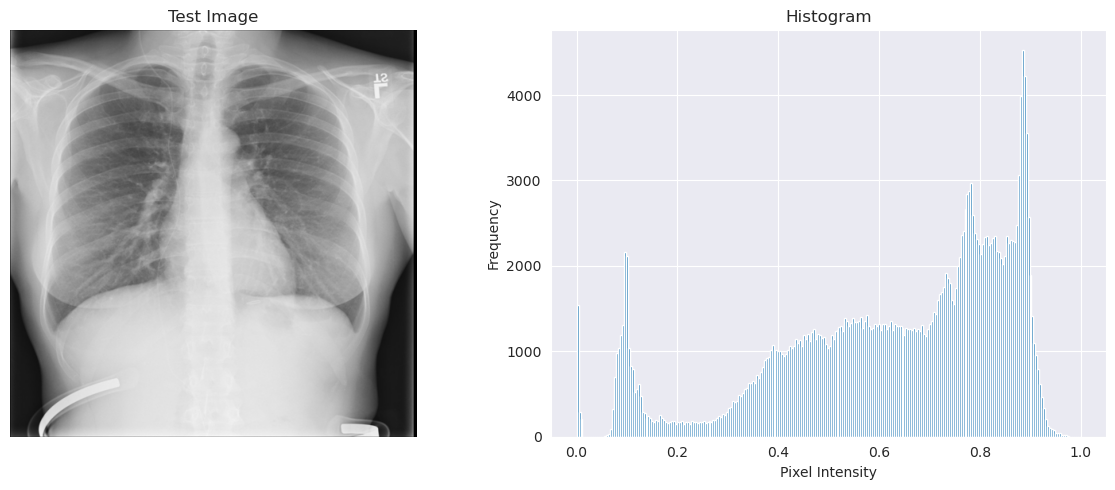

In [104]:
import matplotlib.pyplot as plt

test.reset()

X_batch, Y_batch = next(test)

img = X_batch[0]
gray = img[:,:,0]

plt.figure(figsize=(12,5))

# gambar
plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Test Image")
plt.axis("off")

# histogram
plt.subplot(1,2,2)
plt.hist(
    gray.ravel(),
    bins=256,
    range=(0,1)
)

plt.title("Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [105]:
import numpy as np

y_pred = model.predict(test)
y_pred = y_pred.ravel()

y_true = test.classes

27/27 [==============================] - 15s 530ms/step


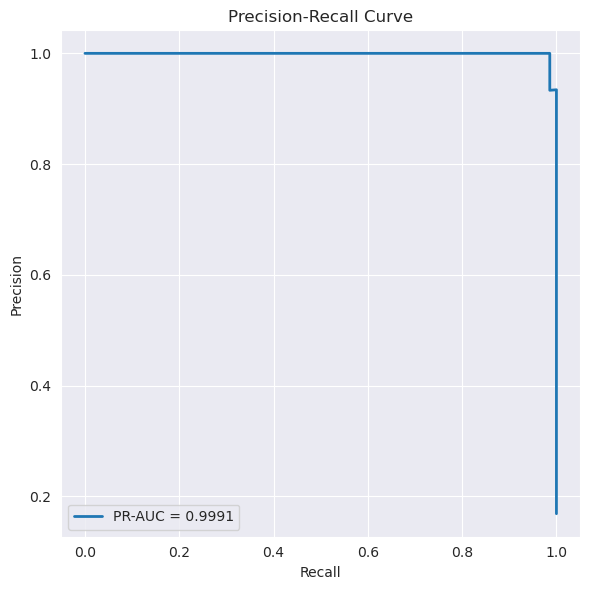

PR-AUC = 0.9990733876945885


In [106]:
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

precision, recall, _ = precision_recall_curve(
    y_true,
    y_pred
)

pr_auc = average_precision_score(
    y_true,
    y_pred
)

plt.figure(figsize=(6,6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f'PR-AUC = {pr_auc:.4f}'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')

plt.tight_layout()
plt.show()

print("PR-AUC =", pr_auc)

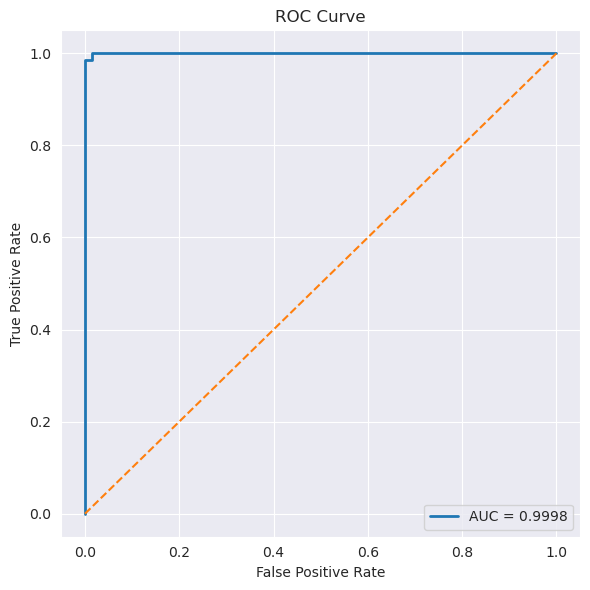

ROC-AUC = 0.9997987927565393


In [107]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))

plt.plot(fpr, tpr,
         linewidth=2,
         label=f'AUC = {roc_auc:.4f}')

plt.plot([0,1], [0,1], '--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

print("ROC-AUC =", roc_auc)

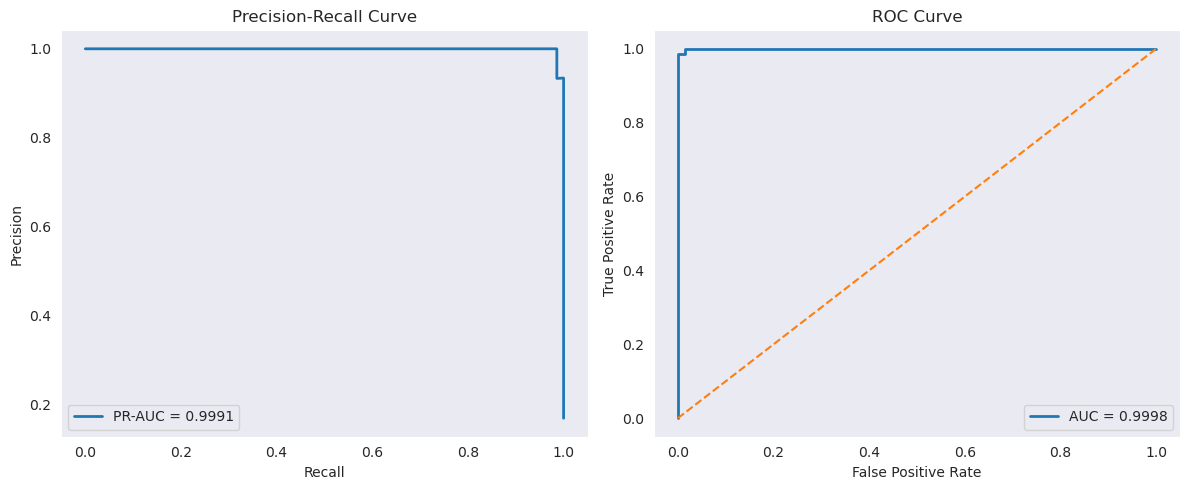

PR-AUC = 0.9990733876945885
ROC-AUC = 0.9997987927565393


In [108]:
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt


# =====================
# Precision-Recall Curve
# =====================

precision, recall, _ = precision_recall_curve(
    y_true,
    y_pred
)

pr_auc = average_precision_score(
    y_true,
    y_pred
)


# =====================
# ROC Curve
# =====================

fpr, tpr, _ = roc_curve(
    y_true,
    y_pred
)

roc_auc = auc(
    fpr,
    tpr
)


# =====================
# Plot side by side
# =====================

fig, ax = plt.subplots(
    1, 2,
    figsize=(12,5)
)


# ---- PR Curve ----
ax[0].plot(
    recall,
    precision,
    linewidth=2,
    label=f'PR-AUC = {pr_auc:.4f}'
)

ax[0].set_xlabel('Recall')
ax[0].set_ylabel('Precision')
ax[0].set_title('Precision-Recall Curve')
ax[0].legend(loc='lower left')
ax[0].grid()


# ---- ROC Curve ----
ax[1].plot(
    fpr,
    tpr,
    linewidth=2,
    label=f'AUC = {roc_auc:.4f}'
)

ax[1].plot(
    [0,1],
    [0,1],
    '--'
)

ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate')
ax[1].set_title('ROC Curve')
ax[1].legend(loc='lower right')
ax[1].grid()


plt.tight_layout()
plt.show()


print("PR-AUC =", pr_auc)
print("ROC-AUC =", roc_auc)

In [110]:
print(model.layers[-1].activation)

<function sigmoid at 0x7dc649a80670>
